# SILLA — 01 · Exploratory Data Analysis
**Owner:** Amr Badr · Data Science & Recommendation
**تحليل استكشافي للوصفات والمكونات والأسعار**

Questions this notebook answers:
1. What does the recipe catalogue look like (categories, cuisines, difficulty, time)?
2. Which ingredients drive the catalogue, and how do they combine?
3. How are product prices distributed across ingredient categories and stores?
4. How much does a meal cost per serving, and what makes it expensive?
5. Which data-quality issues affect recommendation and cost modelling?

Data source: `SILLA_Data_Engineering/database/silla_staging.db` (built by the Data Engineering pipeline).

In [1]:
import sys, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "SILLA_Data_Engineering").exists())
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from SILLA_Data_Science.data_loader import FIGURES_DIR, build_recipe_table, load_tables, unique_recipes

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 60)

# Chart style: one accent colour, quiet axes, light grid
ACCENT, ACCENT_2, ACCENT_3, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ad", "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 11, "axes.labelsize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
})
def save(fig, name):
    fig.tight_layout(); fig.savefig(FIGURES_DIR / f"{name}.png", bbox_inches="tight")

In [2]:
tables = load_tables()
recipes_all = build_recipe_table()          # 320 rows, with costs and diet flags
recipes = unique_recipes(recipes_all)       # one row per dish (see section 1)
ri, ingredients, products, stores = (tables[k] for k in ["recipe_ingredients", "ingredients", "products", "stores"])
ing_name = ingredients.set_index("ingredient_id")["canonical_name_en"]
store_name = stores.set_index("store_id")["store_name"]
pd.DataFrame({name: {"rows": len(df), "columns": df.shape[1], "missing cells": int(df.isna().sum().sum())}
              for name, df in tables.items()}).T

,rows,columns,missing cells
recipes,320,16,0
recipe_ingredients,2730,8,0
ingredients,140,8,0
products,460,16,0
stores,8,5,0


## 1. Data quality
### 1.1 Recipe style variants are duplicates
Many recipe names end with a style suffix such as *(Cairo Street Style)*. These variants have
**exactly the same ingredients and quantities** as their base recipe, so they add no new information.
For recommendation they must never be suggested for each other, and for modelling they must not leak between train and test sets.

In [3]:
fam_sizes = recipes_all.groupby("family_id").size()
ri_sig = ri.sort_values(["recipe_id", "ingredient_id"]).groupby("recipe_id").apply(
    lambda g: tuple(zip(g.ingredient_id, g.quantity, g.unit)))
same = recipes_all.assign(sig=recipes_all.recipe_id.map(ri_sig)).groupby("family_id")["sig"].nunique().eq(1).all()
print(f"Recipes: {len(recipes_all)} | unique dishes (families): {recipes_all.family_id.nunique()} | "
      f"style variants: {recipes_all.is_variant.sum()}")
print("Family sizes:", fam_sizes.value_counts().sort_index().to_dict())
print("Every variant has identical ingredients/quantities to its base recipe:", same)
recipes_all.loc[recipes_all.family_id == "R0002", ["recipe_id", "recipe_name_en", "total_time"]]

Recipes: 320 | unique dishes (families): 155 | style variants: 165
Family sizes: {2: 145, 3: 10}
Every variant has identical ingredients/quantities to its base recipe: True


,recipe_id,recipe_name_en,total_time
1,R0002,Egyptian Koshari,85
156,R0157,Egyptian Koshari (Alexandrian Coastal Style),90
311,R0312,Egyptian Koshari (Cairo Street Style),95


### 1.2 Price coverage
Only ingredients that have a product in the catalogue can be priced. Missing prices are **imputed** with the
median price per gram of the ingredient's category (e.g. *Meat and Poultry*) so that recipes can be compared fairly.

In [4]:
priced_ings = set(products.ingredient_id)
print(f"Ingredients with at least one product: {len(priced_ings)}/{len(ingredients)}")
print(f"Dishes with 100% real prices: {(recipes.price_completeness == 1).sum()}/{len(recipes)}")
print(f"Share of estimated cost that is imputed: {recipes.imputed_cost_egp.sum() / recipes.est_cost_egp.sum():.1%}")
use = ri[ri.recipe_id.isin(recipes.recipe_id)]
missing = (use[~use.ingredient_id.isin(priced_ings)].ingredient_id.value_counts().head(10)
           .rename(index=ing_name).rename("dishes using it"))
missing.to_frame()

Ingredients with at least one product: 98/140
Dishes with 100% real prices: 6/155
Share of estimated cost that is imputed: 32.7%


,dishes using it
ingredient_id,
Fine Salt,131
Vegetable Cooking Oil,29
Whole Milk,28
Fresh Parsley,17
Fresh Dill,12
Mastic Gum,7
Ground Coriander,6
Hot Red Pepper Powder,6
Toast Bread,5


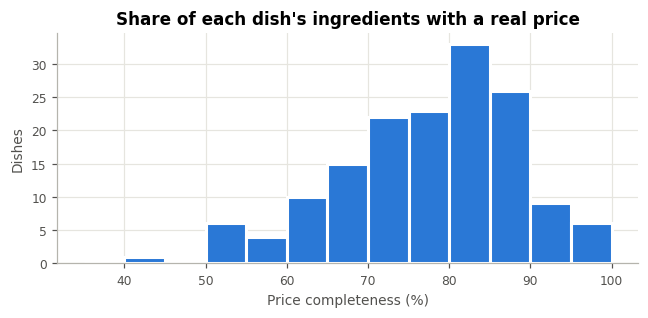

In [5]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(recipes.price_completeness * 100, bins=np.arange(35, 105, 5), color=ACCENT, edgecolor="white", linewidth=2)
ax.set(title="Share of each dish's ingredients with a real price", xlabel="Price completeness (%)", ylabel="Dishes")
save(fig, "eda_price_completeness")

### 1.3 Unit-conversion issue in the shared cost calculator
`SILLA_Recommendation/cost_calculator.py` converts *piece → gram* with a 100 g default for any ingredient missing
from its produce table (whose IDs no longer match the ingredients table). Whole spices are listed in pieces, so
**4 cardamom pods become 400 g (≈ 600 EGP)**. `data_loader.py` applies realistic per-piece weights
(cardamom 0.2 g, bay leaf 0.2 g, clove 0.1 g, cinnamon stick 3 g, mastic 0.1 g, egg 60 g) on top of the calculator output.
*This should also be fixed in the shared module by its owner.*

In [6]:
fix = recipes_all.assign(error=recipes_all.calculator_cost_egp - recipes_all.priced_cost_egp)
print(f"Recipes affected: {(fix.piece_corrections > 0).sum()} | largest over-estimate: {fix.error.max():,.0f} EGP")
fix.nlargest(6, "error")[["recipe_name_en", "calculator_cost_egp", "priced_cost_egp", "error"]]

Recipes affected: 76 | largest over-estimate: 1,427 EGP


,recipe_name_en,calculator_cost_egp,priced_cost_egp,error
61,Smoked Lamb Mandi,1484.91,58.04,1426.87
216,Smoked Lamb Mandi (Alexandrian Coastal Style),1484.91,58.04,1426.87
59,Saudi Lamb Kabsa,1042.91,118.09,924.82
214,Saudi Lamb Kabsa (Spicy Hot Chilli Glazed),1042.91,118.09,924.82
117,Egyptian Kawaraa Tagine In Tomato Vinegar Sauce,1250.88,502.38,748.50
272,Egyptian Kawaraa Tagine In Tomato Vinegar Sauce (Oven-Ba...,1250.88,502.38,748.50


### 1.4 Other observations
- Some recipes are incomplete, e.g. *Egyptian Orzo Chicken Soup* has no chicken in its ingredient list.
- Dietary tags exist per ingredient but `gluten-free` is only set on vegan items, so a recipe-level gluten-free flag would be unreliable. Vegan / vegetarian / pescatarian flags are derived (a recipe is vegetarian when every ingredient is).

## 2. Recipes (unique dishes)

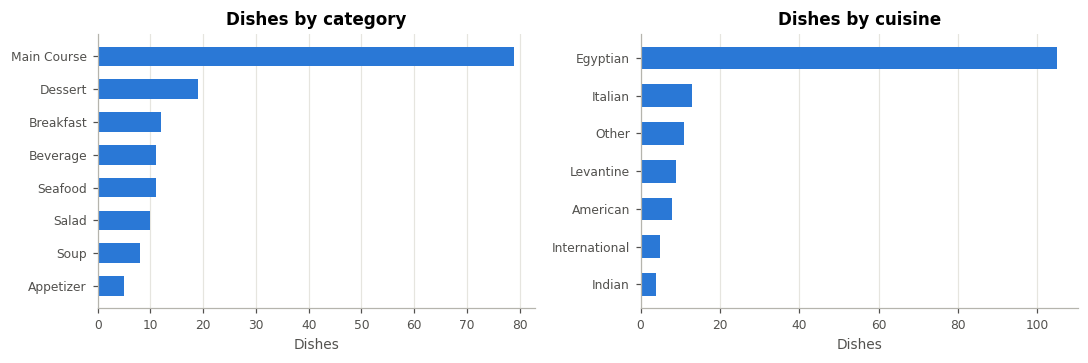

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
c = recipes.category.value_counts().sort_values()
axes[0].barh(c.index, c.values, color=ACCENT, height=0.6); axes[0].set(title="Dishes by category", xlabel="Dishes")
cu = recipes.cuisine.value_counts(); cu = pd.concat([cu.head(6), pd.Series({"Other": cu.iloc[6:].sum()})]).sort_values()
axes[1].barh(cu.index, cu.values, color=ACCENT, height=0.6); axes[1].set(title="Dishes by cuisine", xlabel="Dishes")
for ax in axes: ax.grid(axis="y", visible=False)
save(fig, "eda_category_cuisine")

,base_servings,prep_time,cook_time,total_time,n_ingredients
count,155.0,155.0,155.0,155.0,155.0
mean,4.7,19.4,26.6,46.0,8.5
std,1.3,8.2,22.1,27.0,2.4
min,2.0,3.0,0.0,5.0,2.0
25%,4.0,15.0,12.0,30.0,7.0
50%,4.0,20.0,20.0,40.0,8.0
75%,6.0,25.0,35.0,60.0,10.0
max,8.0,45.0,150.0,180.0,14.0


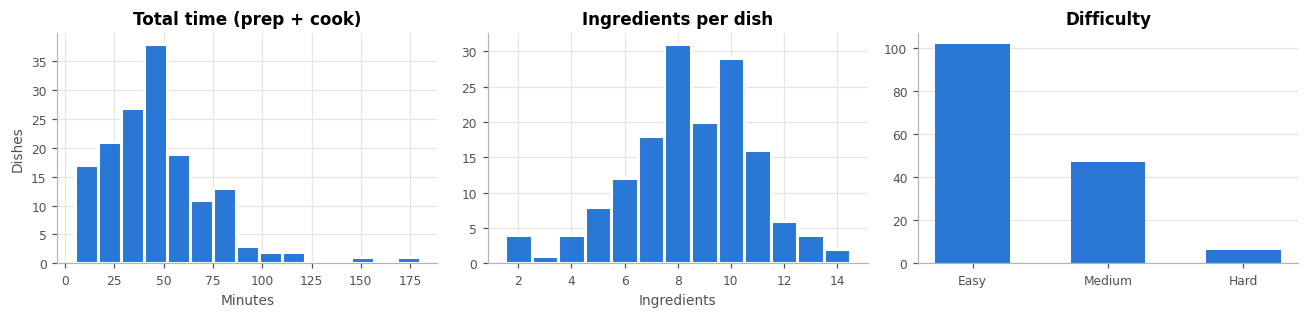

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
axes[0].hist(recipes.total_time, bins=15, color=ACCENT, edgecolor="white", linewidth=2)
axes[0].set(title="Total time (prep + cook)", xlabel="Minutes", ylabel="Dishes")
axes[1].hist(recipes.n_ingredients, bins=np.arange(1.5, 15.5, 1), color=ACCENT, edgecolor="white", linewidth=2)
axes[1].set(title="Ingredients per dish", xlabel="Ingredients")
d = recipes.difficulty.value_counts().reindex(["Easy", "Medium", "Hard"])
axes[2].bar(d.index, d.values, color=ACCENT, width=0.55); axes[2].set(title="Difficulty"); axes[2].grid(axis="x", visible=False)
save(fig, "eda_time_ingredients_difficulty")
recipes[["base_servings", "prep_time", "cook_time", "total_time", "n_ingredients"]].describe().round(1)

In [9]:
diet = recipes[["is_vegan", "is_vegetarian", "is_pescatarian"]].mean().rename(lambda s: s[3:].title()) * 100
diet.round(1).to_frame("% of dishes")

,% of dishes
Vegan,14.8
Vegetarian,43.2
Pescatarian,52.9


## 3. Ingredients

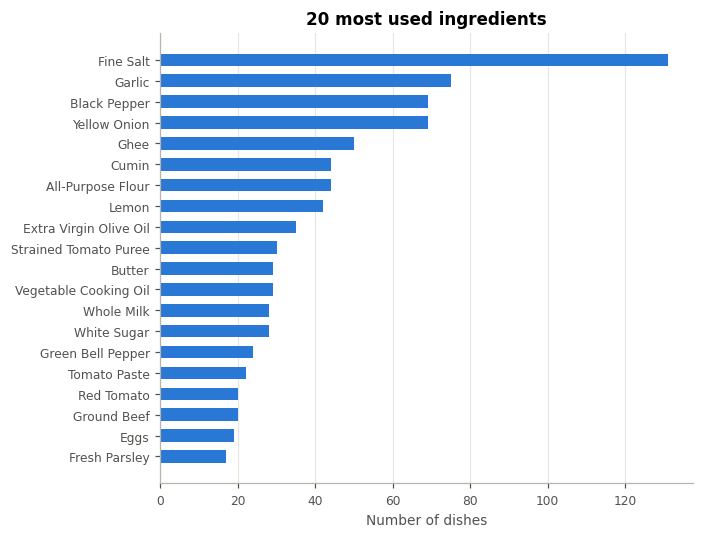

In [10]:
use = ri[ri.recipe_id.isin(recipes.recipe_id)]
top = use.ingredient_id.value_counts().head(20).rename(index=ing_name).sort_values()
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.barh(top.index, top.values, color=ACCENT, height=0.6); ax.grid(axis="y", visible=False)
ax.set(title="20 most used ingredients", xlabel="Number of dishes")
save(fig, "eda_top_ingredients")

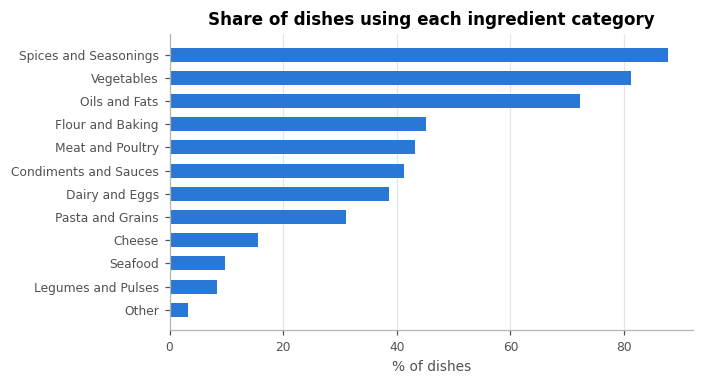

In [11]:
cat_use = use.merge(ingredients[["ingredient_id", "category"]]).groupby("category").recipe_id.nunique().sort_values()
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.barh(cat_use.index, cat_use.values / len(recipes) * 100, color=ACCENT, height=0.6); ax.grid(axis="y", visible=False)
ax.set(title="Share of dishes using each ingredient category", xlabel="% of dishes")
save(fig, "eda_ingredient_categories")

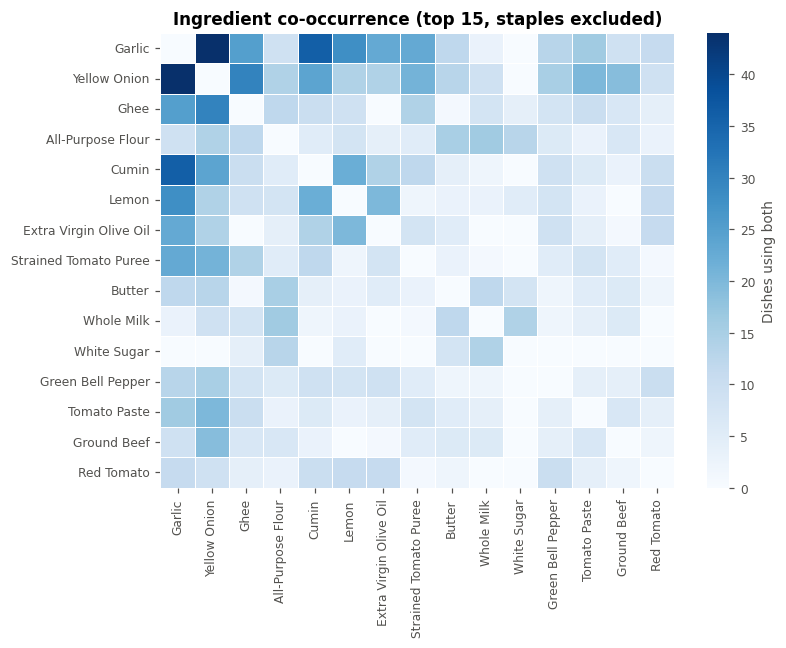

In [12]:
# Co-occurrence of the 15 most common non-staple ingredients
staples = {"ING0051", "ING0012", "ING0126"}  # salt, black pepper, cooking oil
top15 = [i for i in use.ingredient_id.value_counts().index if i not in staples][:15]
m = pd.crosstab(use.recipe_id, use.ingredient_id).clip(upper=1)[top15]
arr = (m.T @ m).to_numpy().copy(); np.fill_diagonal(arr, 0)
names = [ing_name[i] for i in top15]; co = pd.DataFrame(arr, index=names, columns=names)
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(co, cmap="Blues", ax=ax, cbar_kws={"label": "Dishes using both"}, linewidths=0.5, linecolor="white")
ax.set_title("Ingredient co-occurrence (top 15, staples excluded)")
save(fig, "eda_cooccurrence")

## 4. Product prices

,count,min,50%,max
ing_category,,,,
Vegetables,53.0,14.0,36.0,158.1
Pasta and Grains,41.0,34.3,61.2,104.0
Legumes and Pulses,7.0,57.6,84.0,110.0
Condiments and Sauces,22.0,15.7,91.8,325.0
Flour and Baking,200.0,11.0,114.7,2000.0
Dairy and Eggs,40.0,17.3,183.4,490.0
Meat and Poultry,26.0,137.5,292.1,806.0
Spices and Seasonings,24.0,44.1,293.6,1560.0
Cheese,17.0,230.0,312.0,1187.5


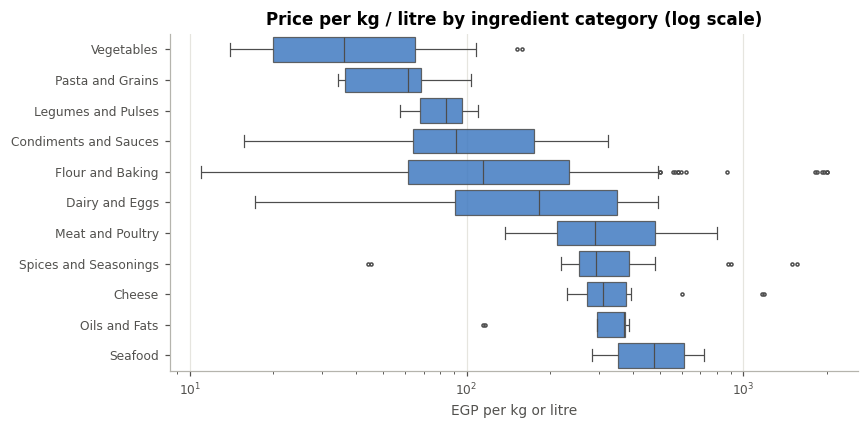

In [13]:
p = products.merge(ingredients[["ingredient_id", "category"]].rename(columns={"category": "ing_category"}), on="ingredient_id")
p["store"] = p.store_id.map(store_name)
p = p[p.package_unit.isin(["g", "ml"])].assign(egp_per_kg=lambda d: d.price_egp / d.package_size * 1000)
order = p.groupby("ing_category").egp_per_kg.median().sort_values().index
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=p, y="ing_category", x="egp_per_kg", order=order, color=ACCENT, ax=ax, fliersize=2, linewidth=0.8,
            boxprops={"alpha": 0.85})
ax.set_xscale("log"); ax.set(title="Price per kg / litre by ingredient category (log scale)", xlabel="EGP per kg or litre", ylabel="")
save(fig, "eda_price_per_kg")
p.groupby("ing_category").egp_per_kg.describe()[["count", "min", "50%", "max"]].round(1).sort_values("50%")

Ingredients sold in more than one store: 83 | median price ratio (most / least expensive store): 1.04x


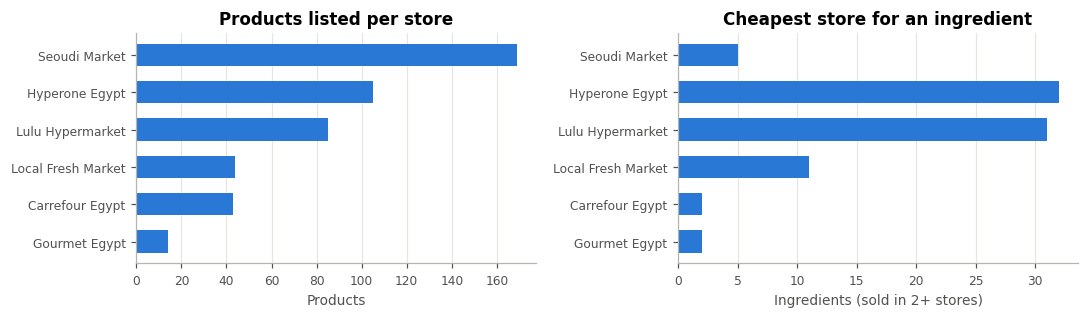

In [14]:
by_store = products.store_id.map(store_name).value_counts().sort_values()
multi = p.groupby("ingredient_id").filter(lambda g: g.store_id.nunique() > 1)
cheapest = multi.loc[multi.groupby("ingredient_id").egp_per_kg.idxmin(), "store"].value_counts().reindex(by_store.index).fillna(0)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].barh(by_store.index, by_store.values, color=ACCENT, height=0.6); axes[0].set(title="Products listed per store", xlabel="Products")
axes[1].barh(cheapest.index, cheapest.values, color=ACCENT, height=0.6)
axes[1].set(title="Cheapest store for an ingredient", xlabel="Ingredients (sold in 2+ stores)")
for ax in axes: ax.grid(axis="y", visible=False)
save(fig, "eda_stores")
spread = multi.groupby("ingredient_id").egp_per_kg.agg(lambda x: x.max() / x.min())
print(f"Ingredients sold in more than one store: {multi.ingredient_id.nunique()} | "
      f"median price ratio (most / least expensive store): {spread.median():.2f}x")

## 5. Meal cost per serving

,count,min,50%,max
category,,,,
Appetizer,5.0,5.0,9.8,12.6
Beverage,11.0,4.1,10.1,48.4
Salad,10.0,5.6,13.6,54.2
Soup,8.0,4.4,19.3,96.9
Dessert,19.0,4.9,21.0,57.1
Breakfast,12.0,4.7,24.6,56.8
Main Course,79.0,11.0,53.2,126.4
Seafood,11.0,79.3,130.4,199.7


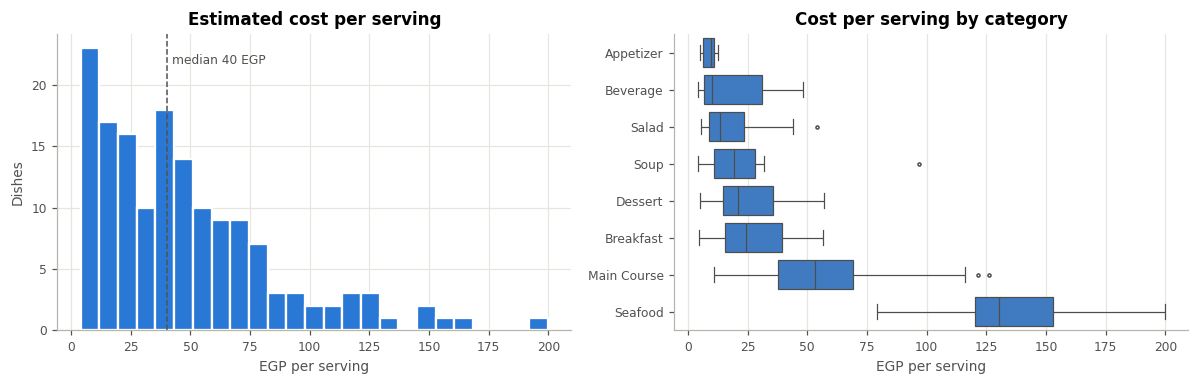

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(recipes.est_cost_per_serving, bins=25, color=ACCENT, edgecolor="white", linewidth=1.5)
axes[0].axvline(recipes.est_cost_per_serving.median(), color=MUTED, ls="--", lw=1)
axes[0].text(recipes.est_cost_per_serving.median() * 1.05, axes[0].get_ylim()[1] * 0.9,
             f"median {recipes.est_cost_per_serving.median():.0f} EGP", fontsize=8, color=MUTED)
axes[0].set(title="Estimated cost per serving", xlabel="EGP per serving", ylabel="Dishes")
order = recipes.groupby("category").est_cost_per_serving.median().sort_values().index
sns.boxplot(data=recipes, y="category", x="est_cost_per_serving", order=order, color=ACCENT, ax=axes[1],
            fliersize=2, linewidth=0.8)
axes[1].set(title="Cost per serving by category", xlabel="EGP per serving", ylabel="")
save(fig, "eda_cost_per_serving")
recipes.groupby("category").est_cost_per_serving.describe()[["count", "min", "50%", "max"]].round(1).sort_values("50%")

In [16]:
cols = ["recipe_name_en", "category", "est_cost_per_serving", "price_completeness"]
pd.concat({"Most expensive": recipes.nlargest(5, "est_cost_per_serving")[cols].reset_index(drop=True),
           "Cheapest": recipes.nsmallest(5, "est_cost_per_serving")[cols].reset_index(drop=True)})

recipe_name_en   category  est_cost_per_serving  price_completeness
Most expensive 0                Singari Sea Bass Alexandrian Style    Seafood                199.73              0.8000
               1                     Crispy Fried Butterfly Shrimp    Seafood                161.41              0.7500
               2                     Baked Sea Bream With Potatoes    Seafood                158.86              0.8000
               3  Grilled Mullet With Wheat Bran (Bouri Bil-Radda)    Seafood                147.05              0.5714
               4                    Alexandrian Spiced Shrimp Soup    Seafood                146.53              0.8000
Cheapest       0                 Iced Egyptian Karkadeh / Hibiscus   Beverage                  4.11              1.0000
               1                        Egyptian Orzo Chicken Soup       Soup                  4.38              0.8333
               2                 Boiled Eggs Rolled In Baladi Ghee  Breakfast                  4.74              0.8000
               3             Classic Chocolate Chip Butter Cookies    Dessert                  4.92              0.8333
               4                        Egyptian Pickled Eggplants  Appetizer                  4.96              0.6250

,est_cost_per_serving
base_servings,-0.22
n Dairy and Eggs,-0.03
n Vegetables,0.15
difficulty_level,0.29
total_time,0.36
n_ingredients,0.43
n Seafood,0.46
n Meat and Poultry,0.53


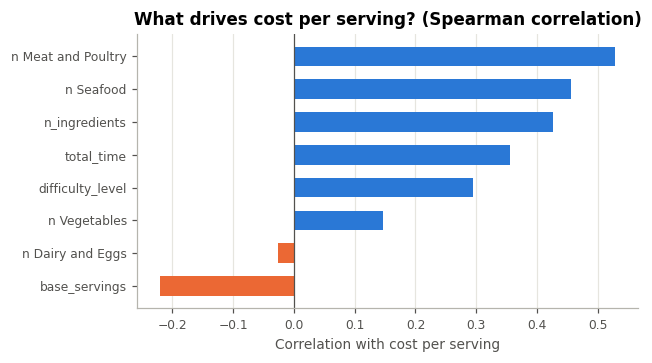

In [17]:
num = recipes[["est_cost_per_serving", "total_time", "n_ingredients", "difficulty_level", "base_servings"]]
mix = use.merge(ingredients[["ingredient_id", "category"]]).pivot_table(index="recipe_id", columns="category",
                                                                       values="ingredient_id", aggfunc="count", fill_value=0)
num = num.set_index(recipes.recipe_id).join(mix[["Meat and Poultry", "Seafood", "Vegetables", "Dairy and Eggs"]].add_prefix("n "))
corr = num.corr(method="spearman")[["est_cost_per_serving"]].drop("est_cost_per_serving").sort_values("est_cost_per_serving")
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.barh(corr.index, corr.est_cost_per_serving, color=[ACCENT if v > 0 else ACCENT_2 for v in corr.est_cost_per_serving], height=0.6)
ax.axvline(0, color=MUTED, lw=0.8); ax.grid(axis="y", visible=False)
ax.set(title="What drives cost per serving? (Spearman correlation)", xlabel="Correlation with cost per serving")
save(fig, "eda_cost_drivers")
corr.round(2)

## 6. Key insights
1. **320 recipes = 155 unique dishes.** 165 recipes are style variants with identical ingredients; recommendation and
   modelling must work at the dish level (family) to avoid duplicate suggestions and train/test leakage.
2. **Egyptian main courses dominate** (≈ two-thirds Egyptian, half Main Course). Small categories (Appetizer, Soup) offer few alternatives.
3. **A few staples appear everywhere** — salt, garlic, onion, black pepper, ghee. Ingredient similarity must down-weight
   them (TF-IDF), otherwise every recipe looks similar.
4. **Protein decides the price.** Seafood and meat/poultry counts are the strongest cost drivers; seafood dishes have the
   highest median cost per serving, drinks/appetizers/salads the lowest. More ingredients and longer cooking also correlate with cost.
5. **Prices are nearly identical across stores** for most ingredients (median price ratio ≈ 1.04×), with Hyperone and Lulu
   most often the cheapest — store choice matters less than recipe choice.
6. **Price coverage is incomplete:** only 6 dishes are 100% priced and about a third of total cost is imputed
   (mostly oil, milk, salt, herbs). Costs are therefore estimates.
7. **A unit-conversion bug** in the shared cost calculator over-prices 76 recipes (up to ≈ 1,400 EGP) by treating spice
   pieces as 100 g; corrected here and reported to the module owner.